In [29]:
import os
os.listdir('/kaggle/input/datasets')

['radheshyamkollipara']

In [30]:
#loading the data set  and quick inspection
import pandas as pd
df = pd.read_csv('/kaggle/input/datasets/radheshyamkollipara/bank-customer-churn/Customer-Churn-Records.csv')
df.head()
df.info()
df.describe()
df.duplicated().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

np.int64(0)

In [31]:
print(df['Exited'].value_counts())
print("\nPercentages:")
print(df['Exited'].value_counts(normalize=True)*100)

Exited
0    7962
1    2038
Name: count, dtype: int64

Percentages:
Exited
0    79.62
1    20.38
Name: proportion, dtype: float64


In [32]:
print("missing values per column:\n",df.isnull().sum())
print("\nDuplicate rows:",df.duplicated().sum())

missing values per column:
 RowNumber             0
CustomerId            0
Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64

Duplicate rows: 0


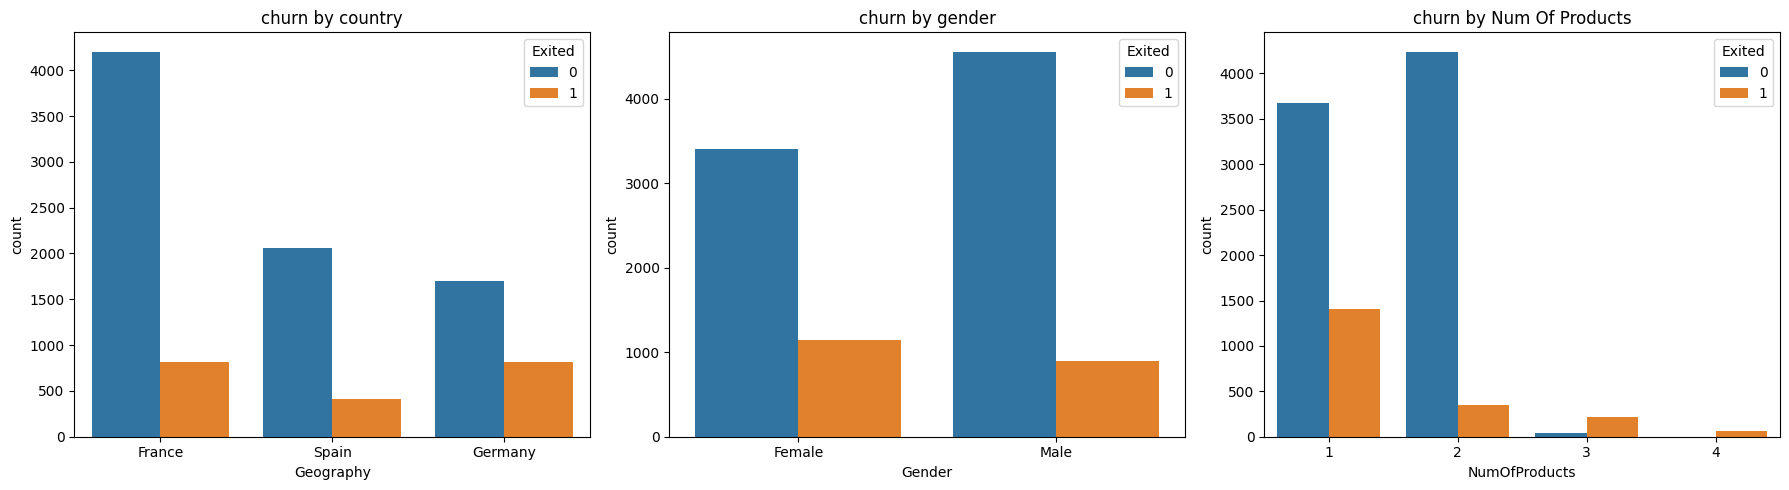

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1,3,figsize =(18,5))

#churn by geography
sns.countplot(data = df , x='Geography' , hue='Exited' ,ax=axes[0])
axes[0].set_title('churn by country')

 #churn by gender
sns.countplot(data=df, x='Gender', hue='Exited' ,ax=axes[1])
axes[1].set_title('churn by gender')

#churn by number of particles
sns.countplot(data=df, x='NumOfProducts', hue='Exited' ,ax=axes[2])
axes[2].set_title('churn by Num Of Products')

plt.tight_layout()
plt.show()



In [34]:
#data preprocessing
#drop non ppredictive columns

cols_to_drop = ['RowNumber','CustomerId','Surname','Complain']
df_clean = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

x = df_clean.drop(columns=['Exited'])
y = df_clean['Exited']
x = pd.get_dummies(x, drop_first=True)
print(x.shape)
x.head()
print(cols_to_drop)

(10000, 16)
['RowNumber', 'CustomerId', 'Surname', 'Complain']


In [35]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("y_train:", y_train.shape)


x_train: (8000, 16)
x_test: (2000, 16)
y_train: (8000,)


In [36]:
#scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("x_train_scaled:", x_train_scaled.shape)

x_train_scaled: (8000, 16)


In [37]:
#train the baseline model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression(max_iter=1000)
model.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaled)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.97      0.89      1592
           1       0.62      0.21      0.32       408

    accuracy                           0.81      2000
   macro avg       0.73      0.59      0.60      2000
weighted avg       0.79      0.81      0.77      2000



In [38]:
import pandas as pd

coefs = pd.Series(model.coef_[0], index=x_train.columns)
print(coefs.abs().sort_values(ascending=False).head(5))

Age                  0.740588
IsActiveMember       0.505266
Geography_Germany    0.357010
Gender_Male          0.263607
Balance              0.162823
dtype: float64


In [39]:
print("Complain" in x_train.columns)

False


In [40]:
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaled)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1592
           1       0.39      0.72      0.51       408

    accuracy                           0.71      2000
   macro avg       0.65      0.72      0.65      2000
weighted avg       0.80      0.71      0.74      2000



In [41]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf.fit(x_train, y_train)

print(classification_report(y_test, rf.predict(x_test)))

              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1592
           1       0.81      0.45      0.58       408

    accuracy                           0.87      2000
   macro avg       0.84      0.71      0.75      2000
weighted avg       0.86      0.87      0.85      2000



In [42]:
proba = rf.predict_proba(x_test)[:, 1]
y_pred_new = (proba >= 0.35).astype(int)
print(classification_report(y_test, y_pred_new))

              precision    recall  f1-score   support

           0       0.91      0.92      0.91      1592
           1       0.67      0.63      0.65       408

    accuracy                           0.86      2000
   macro avg       0.79      0.78      0.78      2000
weighted avg       0.86      0.86      0.86      2000



In [43]:
from sklearn.metrics import roc_auc_score
print("RF AUC:", roc_auc_score(y_test, proba))
print("LR AUC:", roc_auc_score(y_test, model.predict_proba(x_test_scaled)[:, 1]))

RF AUC: 0.868954915508917
LR AUC: 0.7797181372549019


In [44]:
import pandas as pd

imp = pd.Series(rf.feature_importances_, index=x_train.columns)
print(imp.sort_values(ascending=False).head(8))

Age                   0.225625
NumOfProducts         0.122064
Balance               0.112865
EstimatedSalary       0.100506
Point Earned          0.098557
CreditScore           0.095672
Tenure                0.058829
Satisfaction Score    0.039486
dtype: float64


In [45]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(rf, x_train, y_train, cv=5, scoring='roc_auc')
print(scores.mean(), scores.std())

0.8534599493407556 0.007709677370718972


In [ ]:
#Conclusion

Goal Predict which bank customers will churn (Bank Customer Churn dataset, 10,000 customers).

Data leakage The `Complain` column almost perfectly matched `Exited` and gave 100% accuracy. I removed it so the model reflects a realistic prediction task.

Models
- Logistic Regression (balanced): AUC 0.78
- Random Forest: AUC 0.87 (5-fold CV: 0.853 ± 0.008)

Final model Random Forest with a 0.35 decision threshold:
accuracy 0.86, churn recall 0.63, churn precision 0.67, F1 0.65.

Top churn drivers [fill in top 3 from the importance output]

Limitation The threshold was chosen using test-set results, which slightly flatters the metrics.

SyntaxError: invalid character '±' (U+00B1) (800935606.py, line 9)